In [143]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from glob import glob
from tqdm import tqdm
import os
import pickle as pkl
from time import time
import uuid
import zipfile

## Reading the dataset:

In [144]:
# Uncomment if you are in Google Colab:

!pip install wget
import wget, os
url = "https://github.com/IvanSol/ml-course/raw/refs/heads/hs_2026_11/Class08_bvt_classic_cv/data/barcodes.zip"
os.makedirs('data', exist_ok=True)   
wget.download(url, out=os.path.join('data', 'barcodes.zip'))

'data/barcodes (1).zip'

In [145]:
with zipfile.ZipFile('data/barcodes.zip', 'r') as z:
    z.extractall('data/barcodes/')

In [146]:
X_imgs = []
y = []
for label_path in glob('data/barcodes/train/*'):
    label = os.path.basename(label_path)
    for fn in tqdm(glob(os.path.join(label_path, '*.png')), desc=f'Reading label {label}'):
        X_imgs.append(cv2.imread(fn, cv2.IMREAD_GRAYSCALE))
        y.append(label)
y = np.array(y).astype(int)
X_imgs = np.array(X_imgs, dtype="object")

Reading label 3: 100%|██████████| 1000/1000 [00:00<00:00, 1309.78it/s]


0


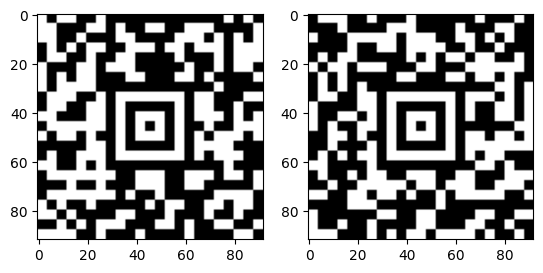

1


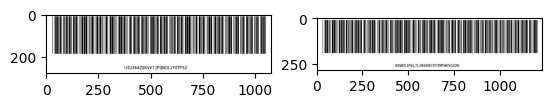

2


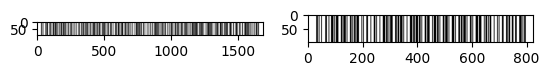

3


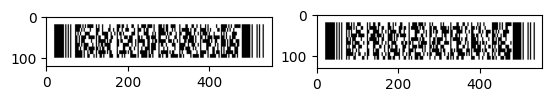

4


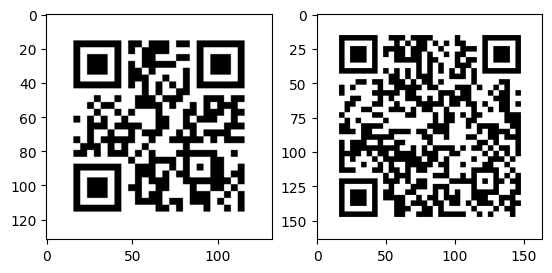

5


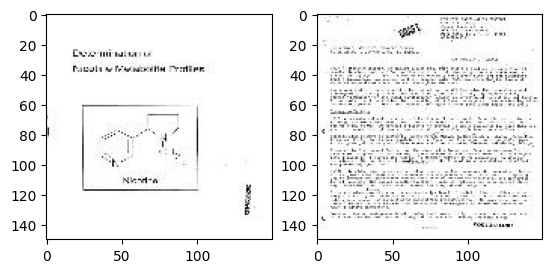

In [147]:
for label in sorted(list(set(y))):
    print(label)
    plt.subplot(121)
    plt.imshow(X_imgs[y == label][0], cmap='gray')
    plt.subplot(122)
    plt.imshow(X_imgs[y == label][100], cmap='gray')
    plt.show()

## Let us try simpliest feature -- ratio of white color on the image.

In [148]:
def get_features(X_imgs, y):
    X = []
    Y = []
    for img, yy in tqdm(zip(X_imgs, y), desc='Extracting features...', total=len(X_imgs)):
        # for rot in range(4):
        #     if rot != 4:
        #         im = cv2.rotate(img, rot)
        #     else:
        #         im = img
        im = img
        X.append([
            (im.astype(float) / 255).sum() / im.size,
            (im[1:] - im[:-1]).sum() / im.size,
            (im[:,1:] - im[:,:-1]).sum() / im.size,
            im.shape[0] / im.shape[1],
        ])
        Y.append(yy)
    X = np.array(X)
    Y = np.array(Y)
    return X, Y

In [149]:
from sklearn.model_selection import train_test_split

In [150]:
X, Y = get_features(X_imgs, y)

Extracting features...: 100%|██████████| 7000/7000 [00:04<00:00, 1657.40it/s]


In [151]:
X_train, X_test, y_train, y_test = train_test_split(X, Y, random_state=42)

In [152]:
from sklearn.linear_model import LogisticRegression as LR

### Only training part of the dataset is labeled. So, it is the only part of the dataset we can use for training and testing.
### Let us try test on the same part we used for training (not a good idea, actually):

In [153]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [154]:
# Here we are training Logistic Regression:
scaler = StandardScaler()
lr = LR()
model = Pipeline([('scaler', scaler), ('LR', lr)])

model.fit(X_train, y_train)

Pipeline(steps=[('scaler', StandardScaler()), ('LR', LogisticRegression())])

#### Calculating the score:

(array([1247., 1926.,  453.,  246.,  128.,    0.,    0.,    0.,    0.,
        3000.]),
 array([0.05509642, 0.14958678, 0.24407713, 0.33856749, 0.43305785,
        0.52754821, 0.62203857, 0.71652893, 0.81101928, 0.90550964,
        1.        ]),
 <BarContainer object of 10 artists>)

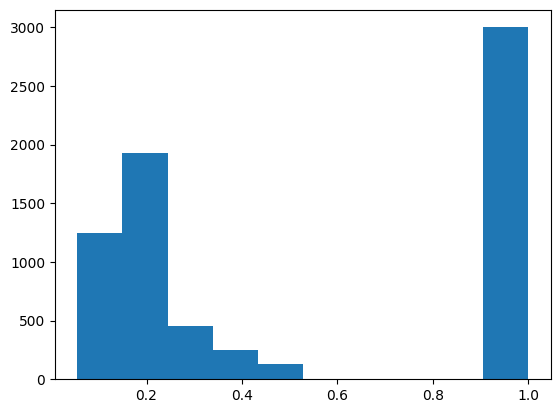

In [155]:
plt.hist(X[:,-1])

In [156]:
model.score(X_test, y_test)

0.9977142857142857

#### Score above is accuracy score. We may calculate it manually by calculating ratio of correct classifications:

In [157]:
y_pred = model.predict(X_test)
print('Accuracy =', (y_pred == y_test).sum() / len(y_test))

Accuracy = 0.9977142857142857


## Let us review testing data and generate resulting file:

In [158]:
X_test_imgs = []
test_names = []
for fn in tqdm(glob('data/barcodes/test/*'), desc='Reading test set'):
    X_test_imgs.append(cv2.imread(fn, cv2.IMREAD_GRAYSCALE))
    test_names.append(os.path.basename(fn))
X_test_imgs = np.array(X_test_imgs, dtype="object")

Reading test set: 100%|██████████| 1750/1750 [00:02<00:00, 621.84it/s]


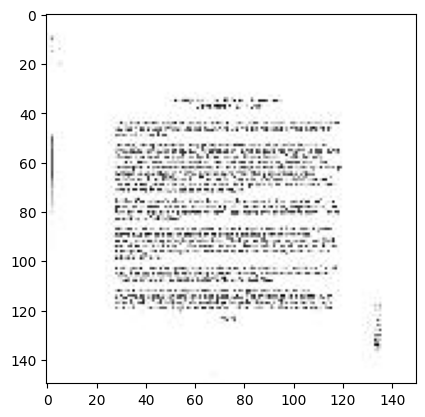

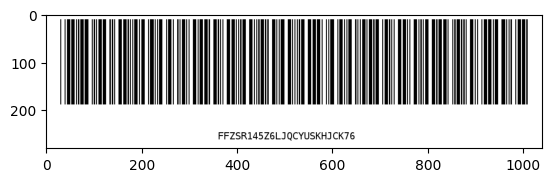

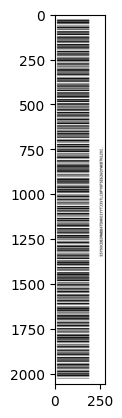

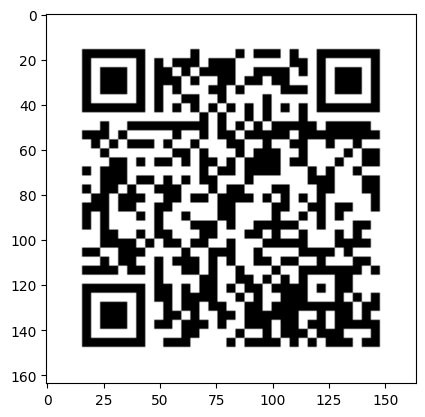

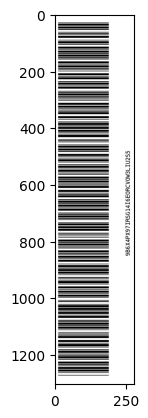

In [159]:
for im in X_test_imgs[:5]:
    plt.imshow(im, cmap='gray')
    plt.show()

## As you may see, images in the dataset can be rotated. You should be able to deal with it.

## Let us generate the answer:

In [160]:
X_test, Y_test = get_features(X_test_imgs, y_test)

Extracting features...: 100%|██████████| 1750/1750 [00:01<00:00, 1558.41it/s]


In [161]:
y_test_pred = model.predict(X_test)

0


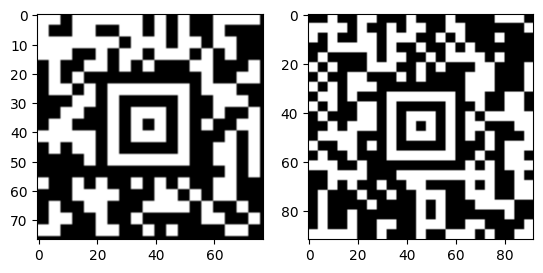

1


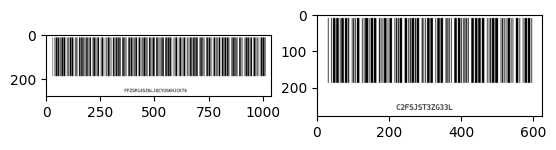

2


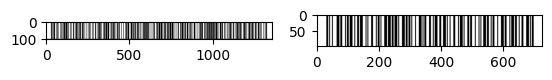

3


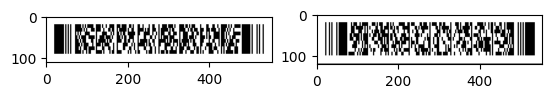

4


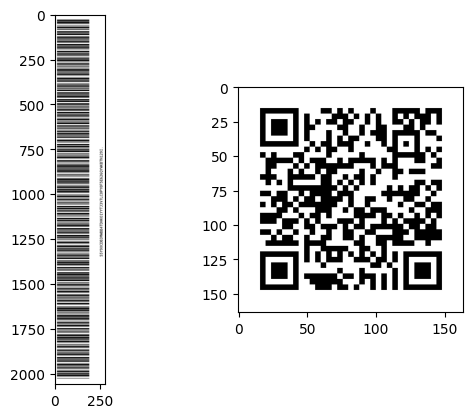

5


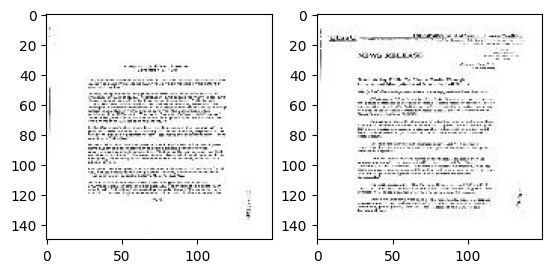

In [162]:
for label in sorted(list(set(y))):
    print(label)
    if (y_test_pred == label).sum() < 6:
        continue
    plt.subplot(121)
    plt.imshow(X_test_imgs[y_test_pred == label][0], cmap='gray')
    plt.subplot(122)
    plt.imshow(X_test_imgs[y_test_pred == label][5], cmap='gray')
    plt.show() 

# Your task is to:
- Find better way to evaluate your model (not to make testing on training set).
- Get higher accuracy (>95% -- 1 point, >97% -- 2 points, >98% -- 3 points, >99% -- 4 points, >99.5% -- 5 pointis).
- Plot confusion matrix for your model (1 point) and ROC curves for each class (1 point).

# Solution

In [163]:
X_imgs = []
y = []
for label_path in glob('data/barcodes/train/*'):
    label = os.path.basename(label_path)
    for fn in tqdm(glob(os.path.join(label_path, '*.png')), desc=f'Reading label {label}'):
        X_imgs.append(cv2.imread(fn, cv2.IMREAD_GRAYSCALE))
        y.append(label)
y = np.array(y).astype(int)
X_imgs = np.array(X_imgs, dtype="object")

Reading label 3: 100%|██████████| 1000/1000 [00:00<00:00, 1380.89it/s]


In [164]:
from sklearn.model_selection import train_test_split

X_train, X_val, y_train, y_val = train_test_split(
    X_imgs, 
    y, 
    test_size=0.2, 
    random_state=67,
    stratify=y
)

rng = np.random.default_rng(67)
def random_rotate(img):
    k = rng.integers(4)
    return img if k == 3 else cv2.rotate(img, int(k))

# train sets don't have rotate version.
X_val_rot = np.array([random_rotate(im) for im in X_val], dtype=object)

In [165]:
F_train, Y_train = get_features(X_train, y_train)
F_val, Y_val = get_features(X_val_rot, y_val)
F_val0, _ = get_features(X_val, y_val)

model = Pipeline([('scaler', StandardScaler()), ('LR', LR(max_iter=2000))])
model.fit(F_train, Y_train)

print("val, no rotation: ", model.score(F_val0, Y_val))
print("val, with rotation: ", model.score(F_val, Y_val))

Extracting features...: 100%|██████████| 1400/1400 [00:00<00:00, 1459.54it/s]

val, no rotation:  0.9971428571428571
val, with rotation:  0.6935714285714286


## Augmentation

In [166]:
def augment(X, y):
    out_X, out_y = [], []
    for im, yy in zip(X, y):
        out_X.append(im)
        for k in range(3):
            out_X.append(cv2.rotate(im, k))
        out_y.extend([yy] * 4)
    return np.array(out_X, dtype=object), np.array(out_y)

X_train_aug, y_train_aug = augment(X_train, y_train)
F_train_aug, Y_train_aug = get_features(X_train_aug, y_train_aug)

Extracting features...: 100%|██████████| 22400/22400 [00:19<00:00, 1134.78it/s]


In [167]:
model_aug = Pipeline([('scaler', StandardScaler()), ('LR', LR(max_iter=2000))])
model_aug.fit(F_train_aug, Y_train_aug)

print("val, no rotation: ", model_aug.score(F_val0, Y_val))
print("val, with rotation: ", model_aug.score(F_val, Y_val))

val, no rotation:  0.9964285714285714
val, with rotation:  0.9828571428571429


## Change features function

In [168]:
def feat(X, W=64, H=32):
    h, w = X.shape
    aspect = max(h, w) / min(h, w)
    if h > w:
        X = cv2.rotate(X, cv2.ROTATE_90_CLOCKWISE)
    X = cv2.resize(X, (W, H)).astype(float) / 255 # make it smaller 
    return np.concatenate([
        X.ravel(),
        X.mean(axis=0),
        X.mean(axis=1),
        [np.log(aspect)],
    ])

def get_new_features(X_imgs, y):
    X = []
    Y = []
    for img, yy in tqdm(zip(X_imgs, y), desc='Extracting new features...', total=len(X_imgs)):
        im = img
        X.append(feat(im))
        Y.append(yy)
    X = np.array(X)
    Y = np.array(Y)
    return X, Y

F_train, Y_train = get_new_features(X_train, y_train)
F_val, Y_val = get_new_features(X_val_rot, y_val)
F_val0, _ = get_new_features(X_val, y_val)

Extracting new features...: 100%|██████████| 1400/1400 [00:00<00:00, 18998.52it/s]


In [169]:
model_new = Pipeline([('scaler', StandardScaler()), ('LR', LR(max_iter=2000))])
model_new.fit(F_train, Y_train)

print("val, no rotation: ", model_new.score(F_val0, Y_val))
print("val, with rotation: ", model_new.score(F_val, Y_val))

val, no rotation:  0.9964285714285714
val, with rotation:  0.8521428571428571


## only 180 Augments + new_feature_Extractor

In [170]:
def augment_180(X, y):
    out_X, out_y = [], []
    for im, yy in zip(X, y):
        out_X.append(im)
        out_X.append(cv2.rotate(im, cv2.ROTATE_180))
        out_y.extend([yy] * 2)
    return np.array(out_X, dtype=object), np.array(out_y)

X_train_aug, y_train_aug = augment_180(X_train, y_train)
F_train_aug, Y_train_aug = get_new_features(X_train_aug, y_train_aug)


Extracting new features...: 100%|██████████| 11200/11200 [00:00<00:00, 15989.68it/s]


In [171]:
model_new_aug = Pipeline([('scaler', StandardScaler()), ('LR', LR(max_iter=2000))])
model_new_aug.fit(F_train_aug, Y_train_aug)

print("val, no rotation: ", model_new_aug.score(F_val0, Y_val))
print("val, with rotation: ", model_new_aug.score(F_val, Y_val))

val, no rotation:  0.9985714285714286
val, with rotation:  0.9964285714285714


## Confusion Matrix and ROC

Extracting new features...: 100%|██████████| 1750/1750 [00:00<00:00, 12243.45it/s]


[np.float64(0.9999958333333333), np.float64(1.0), np.float64(1.0), np.float64(1.0), np.float64(0.9999250000000001), np.float64(0.9965166666666667)]


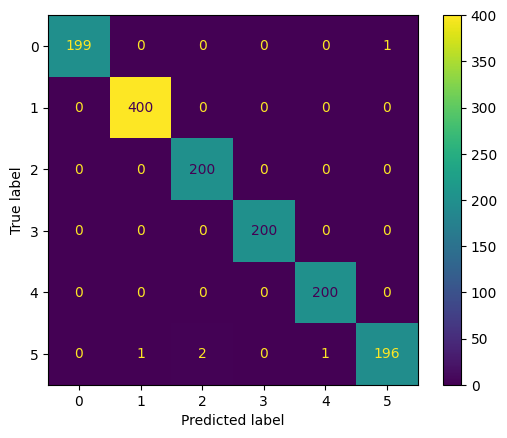

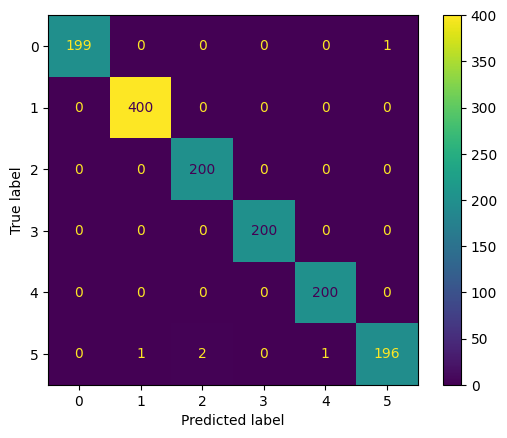

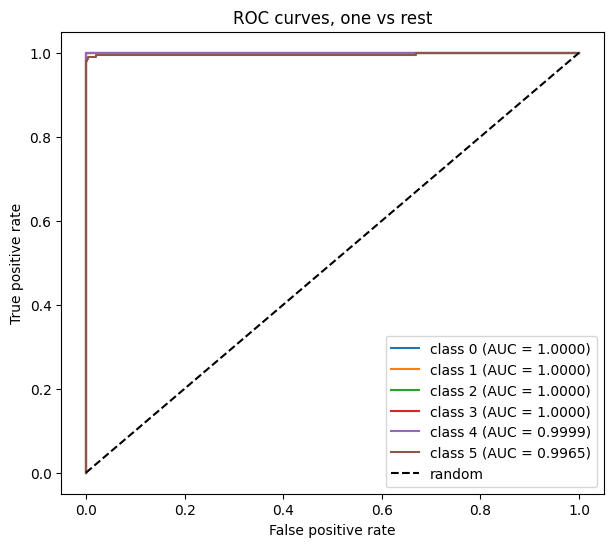

In [172]:
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve, auc, confusion_matrix
from sklearn.preprocessing import label_binarize

F_test, _ = get_new_features(X_test_imgs, np.zeros(len(X_test_imgs)))
y_test_pred = model_new_aug.predict(F_test)
ROC_curves = []

# Note: F_val, Y_val here is new_features
conf_matrix = confusion_matrix(Y_val, model_new_aug.predict(F_val))
ConfusionMatrixDisplay.from_estimator(model_new_aug, F_val, Y_val).plot()

proba = model_new_aug.predict_proba(F_val)
y_bin = label_binarize(Y_val, classes=range(6))

fig, ax = plt.subplots(figsize=(7, 6))
for c in range(6):
    fpr, tpr, _ = roc_curve(y_bin[:, c], proba[:, c])
    ax.plot(fpr, tpr, label=f'class {c} (AUC = {auc(fpr, tpr):.4f})')
ax.plot([0, 1], [0, 1], 'k--', label='random')
ax.set(xlabel='False positive rate', ylabel='True positive rate', title='ROC curves, one vs rest')
ax.legend()
# ax.set_xscale('log')
# ax.set_xlim(0, 0.05)
fig.canvas.draw()
ROC_curves = [roc_auc_score(y_bin[:, c], proba[:, c]) for c in range(6)]
print(ROC_curves)
plt.show()

# Create Submit

In [173]:
answer_to_submit = {fn: yy for fn, yy in zip(test_names, y_test_pred)}

In [174]:
with open('my_answer.pkl', 'wb') as f:
    pkl.dump((answer_to_submit, conf_matrix, ROC_curves, uuid.uuid4().hex, time()), f)
    

### Now submit `my_answer.pkl` to yandex .